# Joint HPP–DC sizing
Native Parallel EGO maximizes annual DC revenue minus annualized HPP/DC costs minus the rational reliability penalty. The unchanged maximum-availability EMS dispatches each candidate. Final acceptance requires independently validated hourly reliability; this is a search result, not a proven global optimum.


In [1]:
from pathlib import Path
from copy import deepcopy
import pandas as pd
from IPython.display import display, Image
from hydesign.sizing_native_joint_hpp_dc_sizing import (
    ROOT, read_configuration, run_native_joint_hpp_dc_sizing, load_joint_hpp_dc_sizing,
    run_joint_revenue_scenarios)
from hydesign.assembly.hpp_assembly_simple_datacenter_joint_hpp_dc_sizing import IT_NAME

config_path = ROOT / 'hydesign/examples/thesis_simple_datacenter/simple_datacenter.yml'
defaults = read_configuration(config_path)
variables = deepcopy(defaults['variables'])
for name in ('Nwt', 'solar_MW [MW AC]', 'b_P [MW]', 'b_E_h [h]'):
    variables[name]['var_type'] = 'design'  # Bounds from YAML; edit limits here if needed.
pue = 1.15
revenue_scenarios = [4000]
outer_time_budget = 60*45
variables[IT_NAME] = dict(var_type='design', types='float',
                         value=16/pue, limits=[20/pue, 70/pue])
config = dict(
    variables=variables, pue=pue, reliability_target=0.999,
    datacenter_firm_revenue_per_mwh_it=revenue_scenarios[0],
    joint_penalty_scaling='reference_revenue',  # Or 'economic_bound' for the original scaling.
    joint_penalty_gamma=0.25,  # Fraction of fixed maximum potential annual IT revenue.
    joint_penalty_mode='rational', joint_penalty_A=2.0,
    joint_penalty_lambda=0.20, joint_penalty_epsilon=0.0001,
    joint_economic_bound_factor=1.0, joint_value_scale_factor=1.0,  # Must be >= 1.
    ems_time_limit_seconds=60, ems_threads=1,
    ems_beta_max_reliability=0.25, ems_kappa_max_reliability=0.10,
    ems_mip_gap_max_reliability=0.0001, ems_seed_max_reliability=0,
    hpp_sizing_time_limit_seconds=outer_time_budget,
    n_procs=2,
    n_doe=16,
    max_iter=1000,
    n_clusters=2,
    npred=10000,
    n_seed=0,
    tol=1e-6,
    min_conv_iter=1000,
    hpp_sizing_output_dir=str(ROOT / 'hpp_sizing_runs/joint_hpp_dc_sizing'),
)
run_fixed_validation = False
saved_run = None  # Set to an existing run directory to load WITHOUT optimizing.
regenerate_saved_figures = False


## Optional fixed design
Uses the YAML reference HPP and 16 MW facility demand. Runs only when explicitly enabled and no saved run is selected.


In [2]:
""" if run_fixed_validation and saved_run is None:
    fixed = deepcopy(config)
    fixed['variables'] = deepcopy(variables)
    for var in fixed['variables'].values():
        var['var_type'] = 'fixed'
    fixed_result = run_native_joint_hpp_dc_sizing(config_path, fixed)
    print(fixed_result['final_status']) """


" if run_fixed_validation and saved_run is None:\n    fixed = deepcopy(config)\n    fixed['variables'] = deepcopy(variables)\n    for var in fixed['variables'].values():\n        var['var_type'] = 'fixed'\n    fixed_result = run_native_joint_hpp_dc_sizing(config_path, fixed)\n    print(fixed_result['final_status']) "

## Joint optimization
The configured search budget covers search and worker startup; cleanup and recovery have separate bounded budgets. Reference-revenue scaling uses J = annual system value - gamma * (8760 * IT revenue rate * maximum IT capacity) * p(excess hours) / A. The reference is fixed over the configured domain; the linear tail means gamma is not a maximum penalty fraction. Below-target candidates may outscore feasible candidates during search, but final acceptance always requires validated reliability. Select economic_bound to reproduce the original scaling; gamma applies only to reference_revenue. Economic validation bounds stay unchanged. Native EGO trains on -J in EUR/year.


In [3]:
# Each execution creates a new batch; summary.csv updates after each scenario.
if saved_run is None:
    batch_directory, revenue_results = run_joint_revenue_scenarios(
        config_path, config, revenue_scenarios)
    print('Combined summary:', batch_directory / 'summary.csv')

    batch_columns = ['revenue_eur_per_mwh_it', 'it_capacity_mw', 'facility_load_mw',
                     'wind_MW', 'PV_MW_AC', 'battery_MW', 'battery_MWh', 'reliability',
                     'lcoe_hpp_eur_per_mwh', 'evaluations', 'status', 'run_directory']
    batch_view = revenue_results.reindex(columns=batch_columns).copy()
    for name, label in {
        'net_annual_value_system': 'Net annual value [MEUR/year]',
        'Revenue_dc': 'DC revenue [MEUR/year]',
        'annualized_cost_hpp': 'HPP annual cost [MEUR/year]',
        'annualized_cost_dc': 'DC annual cost [MEUR/year]',
        'reliability_penalty_eur_per_year': 'Reliability penalty [MEUR/year]',
        'penalized_annual_value': 'EGO objective [MEUR/year]',
    }.items():
        amounts = pd.to_numeric(revenue_results.reindex(columns=[name])[name], errors='coerce') / 1e6
        batch_view[label] = amounts.map(lambda value: f'{value:,.2f}' if pd.notna(value) else '-')
    display(batch_view)
    completed = revenue_results.loc[revenue_results['run_directory'].notna(), 'run_directory']
    if completed.empty:
        raise RuntimeError(f'No run result was saved. Inspect {batch_directory / "summary.csv"}')
    run_directory = completed.iloc[-1]  # Detailed tables below show the last completed scenario.
else:
    run_directory = Path(saved_run)

result, history = load_joint_hpp_dc_sizing(
    run_directory, save_figures=regenerate_saved_figures)


Revenue batch: C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\joint_hpp_dc_sizing\revenue_batch_20261115_181655Z_98f79f91
Revenue assumption [EUR/MWh_IT]: 4000


Combined summary: C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\joint_hpp_dc_sizing\revenue_batch_20261115_181655Z_98f79f91\summary.csv


,revenue_eur_per_mwh_it,it_capacity_mw,facility_load_mw,wind_MW,PV_MW_AC,battery_MW,battery_MWh,reliability,lcoe_hpp_eur_per_mwh,evaluations,status,run_directory,Net annual value [MEUR/year],DC revenue [MEUR/year],HPP annual cost [MEUR/year],DC annual cost [MEUR/year],Reliability penalty [MEUR/year],EGO objective [MEUR/year]
0,4000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ERROR,None,-,-,-,-,-,-


RuntimeError: No run result was saved. Inspect C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\joint_hpp_dc_sizing\revenue_batch_20261115_181655Z_98f79f91\summary.csv

## Results
Below-target time-limited dispatches remain in the evaluation history, with their solver certificates; they are not accepted as final designs.


In [ ]:

print('Results:', run_directory)
print('Status:', result['final_status'])
print('Evaluations:', result.get('evaluated_designs'),
      '| feasible:', result.get('feasible_evaluations'),
      '| search seconds:', result.get('optimization_seconds'))

best = result.get('best')

if best:
    design = best['design']
    pue = result['configuration']['pue']

    summary = {
        # Data center
        'IT capacity [MW]': design[11],
        'Facility demand [MW]': design[11] * pue,

        # Reliability
        'Reliability target [%]': 100 * result['configuration']['reliability_target'],
        'Achieved reliability [%]': 100 * best['metrics']['firm_reliability'],
        'LOLH [h]': best['metrics']['LOLH'],

        # HPP sizing
        'Wind [MW]': design[2] * design[3],
        'PV [MW AC]': design[5],
        'Battery power [MW]': design[9],
        'Battery duration [h]': design[10],
        'Battery energy [MWh]': design[9] * design[10],

        # Economics
        'Net annual system value [MEUR/year]':
            best['economics']['net_annual_value_system'] / 1e6,
        'DC revenue [MEUR/year]':
            best['economics']['Revenue_dc'] / 1e6,
        'Annualized HPP cost [MEUR/year]':
            best['economics']['annualized_cost_hpp'] / 1e6,
        'Annualized DC cost [MEUR/year]':
            best['economics']['annualized_cost_dc'] / 1e6,
        'Reliability penalty [MEUR/year]':
            best['scoring']['reliability_penalty_eur_per_year'] / 1e6,
        'Penalized EGO objective [MEUR/year]':
            best['scoring']['penalized_annual_value'] / 1e6,
        'HPP LCoE [EUR/MWh]': best['lcoe_hpp_eur_per_mwh'],
    }

    summary_table = pd.Series(summary, name='Validated best design').to_frame().astype(object)
    money_rows = [name for name in summary if '[MEUR/year]' in name]
    summary_table.loc[money_rows, 'Validated best design'] = summary_table.loc[
        money_rows, 'Validated best design'].map(lambda value: f'{value:,.2f}')
    display(summary_table)
    print('Penalty scaling:', result['configuration'].get('joint_penalty_scaling', 'economic_bound'))

    print('IT capacity bound:', best['it_capacity_bound'])
    print('Validation:', best['validation'])
    print('EMS status:', {k: best['solver_status'].get(k) for k in
                          ('termination', 'stages', 'certificate', 'binary_failed_hours')})
else:
    print('No validated reliability-feasible design recovered; inspect evaluations.csv.')

# Presentation only: the original history and saved EUR values stay unchanged.
annual_money = {
    'net_annual_value_system': 'Net annual system value [MEUR/year]',
    'Revenue_dc': 'DC revenue [MEUR/year]',
    'annualized_cost_hpp': 'Annualized HPP cost [MEUR/year]',
    'annualized_cost_dc': 'Annualized DC cost [MEUR/year]',
    'reliability_penalty_eur_per_year': 'Reliability penalty [MEUR/year]',
    'score': 'Penalized EGO score / fallback [MEUR/year]',
}
history_columns = ['evaluation_index', 'status', 'Nwt', 'wind_MW', 'solar_MW',
                   'b_P', 'b_E', 'it_capacity_mw', 'reliability', 'failed_hours',
                   'EENS', 'lcoe_hpp_eur_per_mwh', 'joint_penalty_scaling', 'joint_penalty_gamma']
history_view = history.reindex(columns=history_columns).copy()
for name, label in annual_money.items():
    history_view[label] = pd.to_numeric(history.reindex(columns=[name])[name], errors='coerce') / 1e6
history_display = history_view.tail().copy()
for label in annual_money.values():
    history_display[label] = history_display[label].map(
        lambda value: f'{value:,.2f}' if pd.notna(value) else '-')
display(history_display)


Results: \\?\C:\Users\loict\OneDrive\Skrivebord\Master thesis\MSc Modelling\HyDesign\hpp_sizing_runs\joint_hpp_dc_sizing\revenue_batch_20261115_160923Z_4d8ccbd2\scenario_01_revenue_4000_eur_per_mwh_it\20261115_160923Z_bbf3d14a_joint_hpp_dc_sizing
Status: VALIDATED_FEASIBLE_INCUMBENT
Evaluations: 460 | feasible: 102 | search seconds: 5400.0


,Validated best design
IT capacity [MW],33.728043
Facility demand [MW],38.78725
Reliability target [%],99.9
Achieved reliability [%],99.908676
LOLH [h],8.0
Wind [MW],300.0
PV [MW AC],250.0
Battery power [MW],80.0
Battery duration [h],15.0
Battery energy [MWh],1200.0


Penalty scaling: reference_revenue
IT capacity bound: None
Validation: {'metrics': {'LOLH': 8.0, 'firm_reliability': 0.9990867579908675, 'EENS': 302.92388470247124, 'successful_hours': 8752.0, 'total_hours': 8760.0, 'epsilon_mw': 0.001, 'full_load_factor': 0.9990867579908675, 'longest_shortage_hours': 4.0}, 'max_failed_hours': 8, 'outer_feasible': True, 'physical_residuals': {'renewable_balance_mw': 5.684341886080802e-14, 'power_balance_mw': 2.1316282072803006e-14, 'demand_balance_mw': 0.0, 'it_balance_mw': 0.0, 'served_pue_mw': 0.0, 'unserved_pue_mw': 0.0, 'demand_pue_mw': 0.0, 'soc_transition_mwh': 1.5631940186722204e-13}, 'certificate': {'failed_hours_lower_bound': 8, 'failed_hours_upper_bound': 8, 'maximum_availability_certified': True, 'exact_reliability_lower_bound': 0.9990867579908675, 'exact_reliability_upper_bound': 0.9990867579908675, 'certificate_scope': 'exact-service binary count; not epsilon-based LOLH'}}
EMS status: {'termination': 'OPTIMAL_WITHIN_TOLERANCES', 'stages': 

,evaluation_index,status,Nwt,wind_MW,solar_MW,b_P,b_E,it_capacity_mw,reliability,failed_hours,EENS,lcoe_hpp_eur_per_mwh,joint_penalty_scaling,joint_penalty_gamma,Net annual system value [MEUR/year],DC revenue [MEUR/year],Annualized HPP cost [MEUR/year],Annualized DC cost [MEUR/year],Reliability penalty [MEUR/year],Penalized EGO score / fallback [MEUR/year]
456,457,BELOW_TARGET,60.0,300.0,250.00,80.000000,984.962871,33.728043,0.998516,13.0,480.356567,128.350542,reference_revenue,0.25,968.62,"1,180.16",43.55,167.99,101.64,866.98
457,458,INTERRUPTED,57.0,285.0,192.39,75.299500,1118.773616,34.565000,NaN,NaN,NaN,NaN,economic_bound,NaN,-,-,-,-,-,-
458,459,BELOW_TARGET,51.0,255.0,219.21,76.972500,1130.221855,34.601522,0.998402,14.0,546.721062,113.400349,reference_revenue,0.25,998.73,"1,210.54",39.47,172.34,114.35,884.38
459,460,BELOW_TARGET,56.0,280.0,250.00,80.000000,1200.000000,33.728043,0.998973,9.0,348.064965,127.188942,reference_revenue,0.25,969.46,"1,180.62",43.17,167.99,27.71,941.74
460,461,BELOW_TARGET,60.0,300.0,250.00,74.911161,1123.667421,33.728043,0.998858,10.0,364.590189,130.811839,reference_revenue,0.25,968.17,"1,180.56",44.40,167.99,50.81,917.36


## Saved figures and reloading
Each run saves configuration, every candidate checkpoint and valid dispatch, evaluations.csv, result.json, best hourly output, and PNG/PDF figures. Set saved_run in the configuration cell to reload later without EGO or CPLEX. Regeneration creates a fresh figures folder.

Revenue batches are stored under revenue_batch_<timestamp>_<id>/. The batch summary.csv contains one row per revenue assumption, with paths to each run and its evaluations.csv. Pending/error statuses preserve progress; annual monetary CSV values remain in EUR/year.


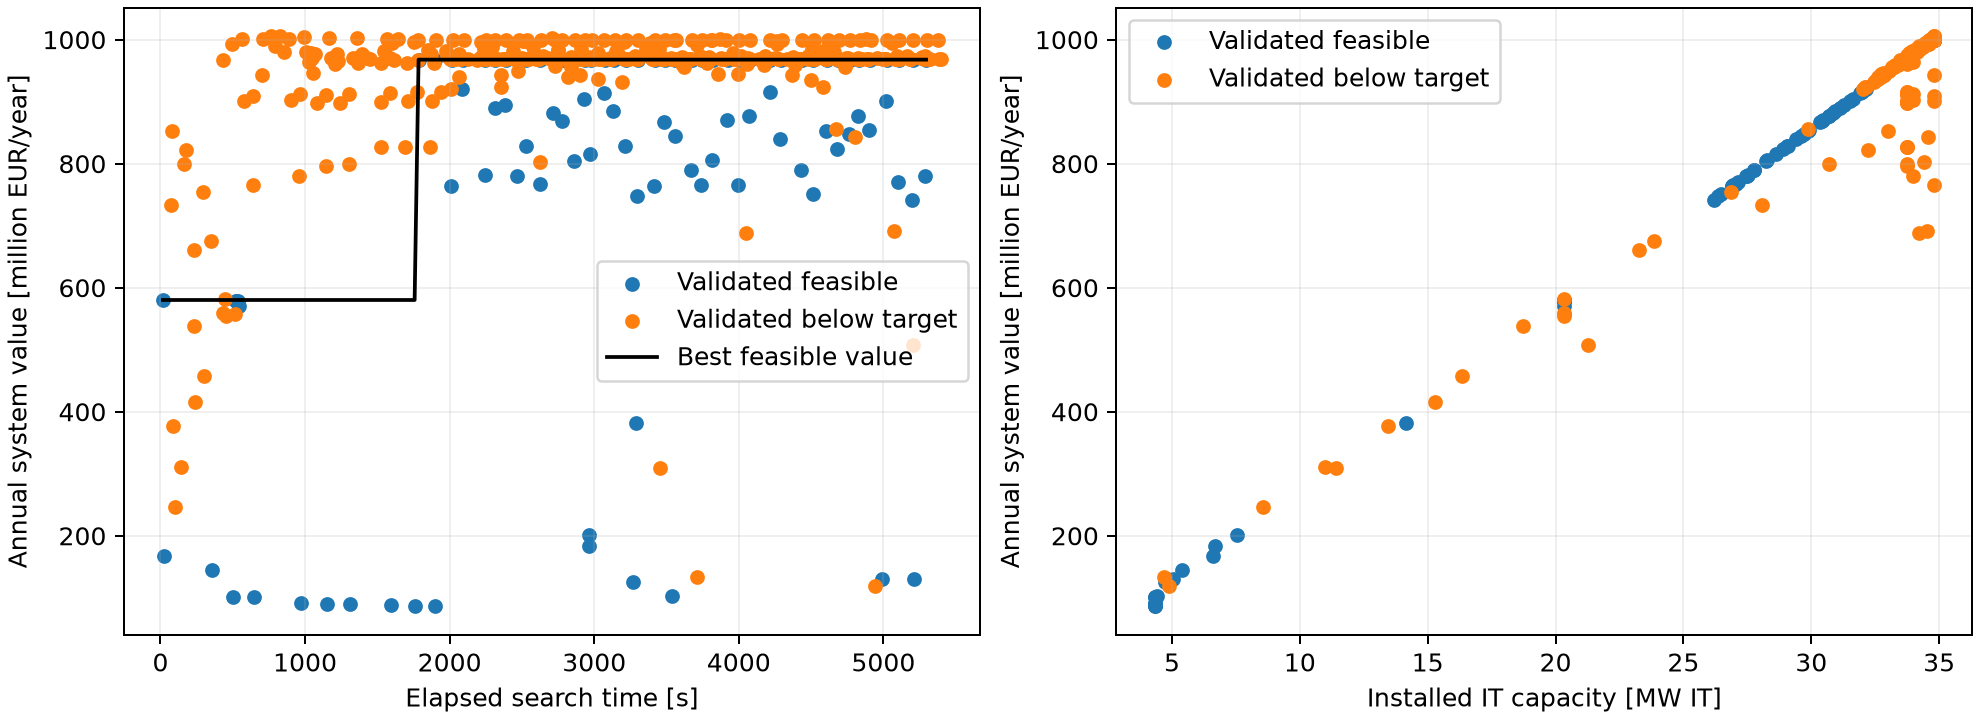

In [ ]:
figure_folders = sorted(Path(run_directory).glob('figures_*'))
if figure_folders:
    plot = figure_folders[-1] / 'joint_hpp_dc_sizing.png'
    if plot.exists():
        display(Image(filename=str(plot)))
